In [2]:
import os
from pprint import pprint
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image
import ceci
import h5py
import yaml

# user specific paths -- IN2P3 example
# my_txpipe_dir = "/pbs/home/m/mricci/throng_mricci/desc/TXPipe"

# user specific paths -- NERSC example
my_txpipe_dir = "/global/cfs/cdirs/m1727/kabelo/TXPipe"

os.chdir(my_txpipe_dir)

import txpipe, txpipe.extensions

In [1]:
def plot_binning(clusters_in, bins_out, zedge, richedge):
    """Plot the input clusters, the bin edges, and the clusters in each output bin."""
    # plot data from input catalog
    plt.semilogy(clusters_in['redshift'], clusters_in['richness'], 'k.', alpha=1)
    plt.xlabel('redshift')
    plt.ylabel('richness')

    # plot bin limits as defined in the config file
    for z in zedge:
        plt.axvline(z, linestyle='dashed', color='black')
    for r in richedge:
        plt.axhline(r, linestyle='dotted', color='black')

    # overplot data from output file to make sure the bins are ordered correctly
    markers = ['s', 'o', 'D', 'P', '^']
    for i in range(len(zedge) - 1):
        for j in range(len(richedge) - 1):
            name = f'bin_zbin_{i}_richbin_{j}'
            plt.scatter(bins_out[name]['redshift'], bins_out[name]['richness'],
                        marker=markers[j % len(markers)], label=name)
    plt.legend(fontsize='x-small', bbox_to_anchor=(1.02, 1), loc='upper left')

In [3]:
fname = "/pscratch/sd/k/kabelo/dp2/external_0723_x_dp2.hdf5" 
with h5py.File(fname, 'r') as f_in:
    clusters_in = {col: f_in['clusters'][col][:] for col in f_in['clusters']}

print(f"{clusters_in['redshift'].size} clusters in the input catalog")
print(clusters_in.keys())

4032 clusters in the input catalog
dict_keys(['cluster_id', 'dec', 'ra', 'redshift', 'redshift_err', 'richness', 'richness_err', 'scaleval'])


In [4]:
with open("/global/u2/k/kabelo/CL_JKcovariance_testing/dp2/common/config.yml", 'r') as file:
    cfg = yaml.safe_load(file)

In [8]:
zedge = cfg["CLClusterBinningRedshiftRichness"]["zedge"]
richedge = cfg["CLClusterBinningRedshiftRichness"]["richedge"]

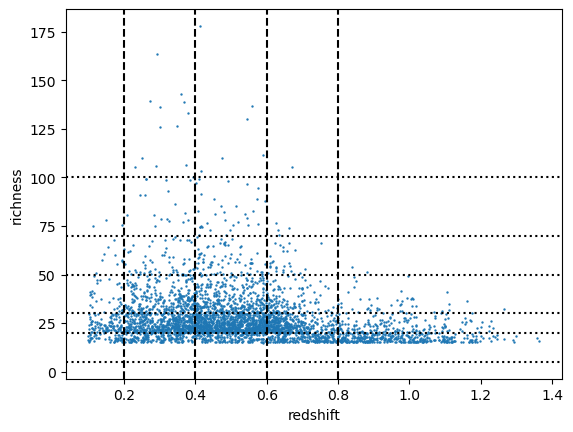

In [13]:
plt.scatter(clusters_in['redshift'], clusters_in['richness'], s=0.5, alpha=1)
plt.xlabel('redshift')
plt.ylabel('richness')

# plot bin limits as defined in the config file
for z in zedge:
    plt.axvline(z, linestyle='dashed', color='black')
for r in richedge:
    plt.axhline(r, linestyle='dotted', color='black')